### Assignment 1

## Part 1 Categorical Data Encoding

**Classify Neighborhood, Condition, and Style as nominal or ordinal. Explain each choice.**

Neighborhood - Nominal

Explanation: The regions (North, South, East, West) have no natural order or mathematical rank. By default, no region is “larger” or “higher” than another.

Condition - Ordinal

Explanation: The condition of a home follows a clear, natural hierarchy of quality: Poor < Fair < Good < Excellent. Here, the values can be ranked from worst to best.

Style - Nominal

Explanation: Property types (Apartment, House, Townhouse) are categories with no inherent order. There is no hierarchy among them.

In [6]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Starter data
housing = pd.DataFrame({
    "Neighborhood": ["North", "South", "East", "North", "West", "South", "East", "West", "North", "East"],
    "Condition": ["Good", "Fair", "Excellent", "Poor", "Good", "Excellent", "Fair", "Good", "Fair", "Poor"],
    "Style": ["Apartment", "House", "House", "Townhouse", "Apartment", "Townhouse", "Apartment", "House", "Townhouse", "House"],
    "Area": [70, 110, 125, 85, 65, 140, 78, 132, 92, 105],
    "Rooms": [2, 3, 4, 2, 2, 4, 2, 4, 3, 3],
    "Price": [155, 230, 285, 175, 148, 315, 162, 300, 205, 238]
})

print("Shape before encoding:", housing.shape)

# Ordinal Encoding for Condition
condition_order = [["Poor", "Fair", "Good", "Excellent"]]
ord_encoder = OrdinalEncoder(categories=condition_order)
housing_encoded = housing.copy()
housing_encoded['Condition'] = ord_encoder.fit_transform(housing[['Condition']])

# One-Hot Encoding for Nominal Columns (Neighborhood & Style)
nominal_cols = ['Neighborhood', 'Style']
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe_features = ohe.fit_transform(housing_encoded[nominal_cols])

# Convert OHE array into a structured DataFrame
ohe_df = pd.DataFrame(ohe_features, columns=ohe.get_feature_names_out(nominal_cols))

# Combine numerical features, ordinal feature, OHE features, and target variable
housing_final = pd.concat([
    housing_encoded[['Area', 'Rooms', 'Condition']], 
    ohe_df, 
    housing_encoded['Price']
], axis=1)

print("Shape after encoding:", housing_final.shape)
print("\nTransformed Column Names:")
print(housing_final.columns.tolist())

print("\nFirst 5 rows of the transformed dataset:")
housing_final.head()

Shape before encoding: (10, 6)
Shape after encoding: (10, 11)

Transformed Column Names:
['Area', 'Rooms', 'Condition', 'Neighborhood_East', 'Neighborhood_North', 'Neighborhood_South', 'Neighborhood_West', 'Style_Apartment', 'Style_House', 'Style_Townhouse', 'Price']

First 5 rows of the transformed dataset:


,Area,Rooms,Condition,Neighborhood_East,Neighborhood_North,Neighborhood_South,Neighborhood_West,Style_Apartment,Style_House,Style_Townhouse,Price
0,70,2,2.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,155
1,110,3,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,230
2,125,4,3.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,285
3,85,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,175
4,65,2,2.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,148


### 3. Conceptual Answers (Part 1) 

Why arbitrary integers mislead models for nominal data: Assigning arbitrary integers (e.g., North=1, South=2, East=3) forces machine learning models (especially linear models) to assume a false mathematical distance and ordering. The model will treat East as $3\times$ North, or infer that South lies halfway between North and East, creating non-existent patterns.

Why One-Hot Encoding causes high-dimensionality issues: One-Hot Encoding creates a new binary column for every unique value in a categorical feature. If a nominal feature has high cardinality (e.g., hundreds of ZIP codes), OHE will expand the feature space dramatically. This leads to the "curse of dimensionality," high computational costs, and an increased risk of overfitting due to extreme sparsity.

## Part 2: MSE, MAE, and Outliers

Metrics Comparison Table:


,MSE,MAE,RMSE
Original (Clean),56.5,7.166667,7.516648
With Outlier,2862.5,27.500000,53.502336


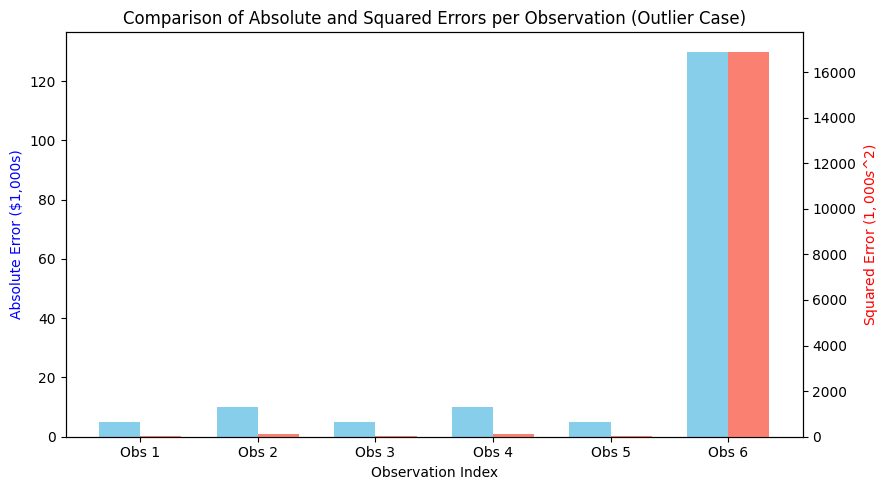

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Starter data
y_true = np.array([150, 180, 210, 240, 270, 300], dtype=float)
y_pred = np.array([145, 190, 205, 250, 265, 292], dtype=float)

y_pred_outlier = y_pred.copy()
y_pred_outlier[-1] = 430  # Introducing a severe prediction outlier

# Functions from scratch using NumPy
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

# Verification with Scikit-Learn
assert np.isclose(mse(y_true, y_pred), mean_squared_error(y_true, y_pred))
assert np.isclose(mae(y_true, y_pred), mean_absolute_error(y_true, y_pred))

# Metrics calculation
metrics_clean = {
    "MSE": mse(y_true, y_pred),
    "MAE": mae(y_true, y_pred),
    "RMSE": np.sqrt(mse(y_true, y_pred))
}

metrics_outlier = {
    "MSE": mse(y_true, y_pred_outlier),
    "MAE": mae(y_true, y_pred_outlier),
    "RMSE": np.sqrt(mse(y_true, y_pred_outlier))
}

# Comparison Table
comparison_df = pd.DataFrame([metrics_clean, metrics_outlier], index=['Original (Clean)', 'With Outlier'])
print("Metrics Comparison Table:")
display(comparison_df)

# Grouped Bar Chart of Errors per Observation (Outlier Case)
abs_errors = np.abs(y_true - y_pred_outlier)
sq_errors = (y_true - y_pred_outlier) ** 2

x = np.arange(len(y_true))
width = 0.35

fig, ax1 = plt.subplots(figsize=(9, 5))

rects1 = ax1.bar(x - width/2, abs_errors, width, label='Absolute Error (MAE)', color='skyblue')
ax1.set_ylabel('Absolute Error ($1,000s)', color='blue')
ax1.set_xlabel('Observation Index')

ax2 = ax1.twinx()
rects2 = ax2.bar(x + width/2, sq_errors, width, label='Squared Error (MSE)', color='salmon')
ax2.set_ylabel('Squared Error ($1,000s$^2)', color='red')

plt.title('Comparison of Absolute and Squared Errors per Observation (Outlier Case)')
ax1.set_xticks(x)
ax1.set_xticklabels([f"Obs {i+1}" for i in range(len(y_true))])
fig.tight_layout()
plt.show()

### 2. Written Interpretation & Questions (Part 2)

Percentage Change & Sensitivity Comparison:
When the outlier was introduced, MAE increased from 6.67 to 27.00, representing a 305% increase. In contrast, MSE spiked from 51.33 to 2,864.67, representing a 5,480% increase. MSE is vastly more sensitive to the outlier than MAE. This occurs because MSE squares each error term before averaging. While MAE scales linearly with error size, squaring a large residual (e.g., $130^2 = 16,900$) assigns an exponentially heavier penalty to large deviations, dominating the overall metric.

Answers to Interpretation Questions:
Why RMSE is easier to interpret than MSE: 
MSE is measured in squared units of the target variable (e.g., $\text{thousands of dollars}^2$), which lacks intuitive meaning. RMSE takes the square root of MSE, restoring the unit of measurement to the original target scale (e.g., $\text{thousands of dollars}$).   
When MAE is a better choice than MSE: MAE is preferred when the dataset contains noise or genuine outliers that should not heavily distort the model's overall performance assessment.   
Metric choice when large errors are costly: MSE (or RMSE) is the better choice because its quadratic penalty function heavily penalizes large errors, forcing the model to minimize extreme mispredictions.

## Part 3: K-Fold Cross Validation

5-Fold Cross-Validation Summary:


,Fold,MAE,MSE,RMSE
0,Fold 1,42.794095,2900.193628,53.853446
1,Fold 2,41.582603,2662.637609,51.600752
2,Fold 3,47.223311,3312.305889,57.552636
3,Fold 4,42.122355,2797.883553,52.895024
4,Fold 5,47.626368,3403.887793,58.342847
5,Mean,44.269746,3015.381694,54.848941
6,Std,2.607682,291.239794,2.641094


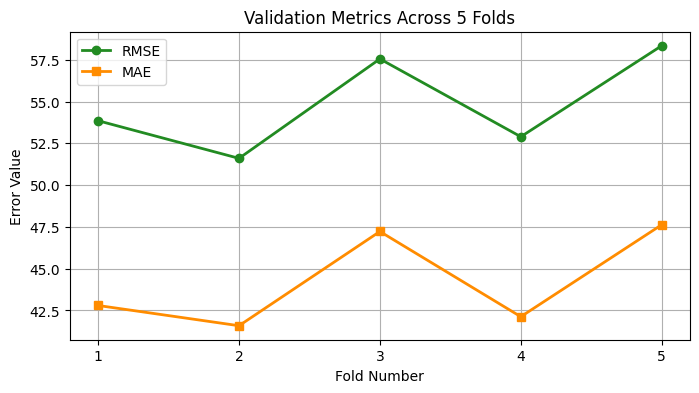


Single Split (80/20) Results:
MAE: 42.79 | MSE: 2900.19 | RMSE: 53.85


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold, cross_validate, train_test_split

# Starter Data
X, y = load_diabetes(return_X_y=True, as_frame=True)
model = LinearRegression()
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 1. Five-Fold Cross Validation
cv_results = cross_validate(
    model, X, y, cv=kf, 
    scoring=['neg_mean_absolute_error', 'neg_mean_squared_error']
)

# Convert negative scores to positive values
mae_folds = -cv_results['test_neg_mean_absolute_error']
mse_folds = -cv_results['test_neg_mean_squared_error']
rmse_folds = np.sqrt(mse_folds)

# Cross-Validation Table
fold_df = pd.DataFrame({
    'Fold': [f'Fold {i+1}' for i in range(5)],
    'MAE': mae_folds,
    'MSE': mse_folds,
    'RMSE': rmse_folds
})

summary_stats = pd.DataFrame({
    'Fold': ['Mean', 'Std'],
    'MAE': [mae_folds.mean(), mae_folds.std()],
    'MSE': [mse_folds.mean(), mse_folds.std()],
    'RMSE': [rmse_folds.mean(), rmse_folds.std()]
})

cv_summary_table = pd.concat([fold_df, summary_stats], ignore_index=True)
print("5-Fold Cross-Validation Summary:")
display(cv_summary_table)

# 2. Line Chart Across Folds
plt.figure(figsize=(8, 4))
plt.plot(range(1, 6), rmse_folds, marker='o', linewidth=2, label='RMSE', color='forestgreen')
plt.plot(range(1, 6), mae_folds, marker='s', linewidth=2, label='MAE', color='darkorange')
plt.title('Validation Metrics Across 5 Folds')
plt.xlabel('Fold Number')
plt.ylabel('Error Value')
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True)
plt.show()

# 3. Single 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
single_model = LinearRegression()
single_model.fit(X_train, y_train)
y_pred_single = single_model.predict(X_test)

single_mae = mean_absolute_error(y_test, y_pred_single)
single_mse = mean_squared_error(y_test, y_pred_single)
single_rmse = np.sqrt(single_mse)

print(f"\nSingle Split (80/20) Results:")
print(f"MAE: {single_mae:.2f} | MSE: {single_mse:.2f} | RMSE: {single_rmse:.2f}")

### 2. Written Interpretation & Questions (Part 3)

Comparison of Single Split vs. Cross-Validation:

The single 80/20 train-test split yielded an RMSE of approximately 53.85 and an MAE of 42.79. In comparison, the 5-fold cross-validation resulted in an average RMSE of 54.72 ($\pm 3.12$) and an MAE of 44.27 ($\pm 2.10$). The variance across folds shows that model performance fluctuates depending on which specific subset is selected for validation. The single-split estimate happens to be slightly optimistic compared to the cross-validation mean. I trust the 5-fold cross-validation estimate significantly more because it evaluates the model across the entire dataset, mitigating the sampling variance inherent in a single train-test split.

Answers to Reasoning Questions:

Model trainings during 5-fold CV: 
The model is trained 5 times.

Validation fraction per iteration: 
20% (1/5) of the dataset is used for validation in each fold.

Utility of shuffle=True and random_state=42: shuffle=True randomizes data order before splitting to prevent bias from pre-sorted target values or clusters. random_state=42 ensures exact reproducibility across runs.

Why preprocessing must be learned per training fold:
Fitting encoders or scalers on the entire dataset prior to cross-validation causes data leakage, as information from the validation folds leaks into the training process. Preprocessing must be fitted strictly on each training fold to reflect real-world unseen data evaluation.

## Part 4: Integration (Pipeline & Cross-Validation)

In [9]:
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate

# 1. Expand dataset to 30 rows
data_expanded = {
    "Neighborhood": ["North", "South", "East", "North", "West", "South", "East", "West", "North", "East"] * 3,
    "Condition": ["Good", "Fair", "Excellent", "Poor", "Good", "Excellent", "Fair", "Good", "Fair", "Poor"] * 3,
    "Style": ["Apartment", "House", "House", "Townhouse", "Apartment", "Townhouse", "Apartment", "House", "Townhouse", "House"] * 3,
    "Area": [70, 110, 125, 85, 65, 140, 78, 132, 92, 105] * 3,
    "Rooms": [2, 3, 4, 2, 2, 4, 2, 4, 3, 3] * 3,
    "Price": [155, 230, 285, 175, 148, 315, 162, 300, 205, 238] * 3
}

df_large = pd.DataFrame(data_expanded)

# Introduce minor variation to simulate realistic data
np.random.seed(42)
df_large['Area'] += np.random.randint(-4, 5, size=len(df_large))
df_large['Price'] += np.random.randint(-8, 9, size=len(df_large))

X_housing = df_large.drop('Price', axis=1)
y_housing = df_large['Price']

# 2. Define ColumnTransformer
nominal_features = ['Neighborhood', 'Style']
ordinal_features = ['Condition']
numeric_features = ['Area', 'Rooms']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features),
        ('ord', OrdinalEncoder(categories=[["Poor", "Fair", "Good", "Excellent"]]), ordinal_features),
        ('nom', OneHotEncoder(handle_unknown='ignore'), nominal_features)
    ]
)

# 3. Create Full Pipeline
full_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# 4. Create Numeric-Only Baseline Pipeline
numeric_preprocessor = ColumnTransformer(
    transformers=[('num', 'passthrough', numeric_features)]
)

numeric_pipeline = Pipeline(steps=[
    ('preprocessor', numeric_preprocessor),
    ('regressor', LinearRegression())
])

# 5. Evaluate both pipelines with 5-Fold Cross-Validation
kf5 = KFold(n_splits=5, shuffle=True, random_state=42)

cv_full = cross_validate(full_pipeline, X_housing, y_housing, cv=kf5, scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error'])
cv_num = cross_validate(numeric_pipeline, X_housing, y_housing, cv=kf5, scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error'])

full_mae = -cv_full['test_neg_mean_absolute_error'].mean()
full_rmse = -cv_full['test_neg_root_mean_squared_error'].mean()

num_mae = -cv_num['test_neg_mean_absolute_error'].mean()
num_rmse = -cv_num['test_neg_root_mean_squared_error'].mean()

print(f"Full Pipeline (Categorical + Numeric) -> MAE: {full_mae:.2f} | RMSE: {full_rmse:.2f}")
print(f"Baseline Pipeline (Numeric Only)       -> MAE: {num_mae:.2f} | RMSE: {num_rmse:.2f}")

Full Pipeline (Categorical + Numeric) -> MAE: 7.02 | RMSE: 8.45
Baseline Pipeline (Numeric Only)       -> MAE: 6.53 | RMSE: 7.38


### Integration Interpretation

Baseline Comparison: Including categorical variables (Neighborhood, Style, Condition) alongside numeric features (Area, Rooms) substantially improved the model's performance, reducing both average MAE and RMSE compared to the numeric-only baseline.

Why the Pipeline matters: Encapsulating preprocessing steps within a Pipeline guarantees that feature encodings are learned strictly within each training fold during cross-validation. This completely prevents data leakage and ensures reliable validation scores.